# Fraud Detection in Electricity and Gas Consumption

Team project based on the Zindi challenge
[Fraud Detection in Electricity and Gas Consumption](https://zindi.africa/competitions/fraud-detection-in-electricity-and-gas-consumption-challenge).
The notebook follows the 7-stage ML blueprint:

1. Data Ingestion & Problem Framing
2. Train/Test Split & EDA Light
3. Cleaning & Feature Preprocessing
4. Baselines & Feature Selection
5. Model Exploration & CV
6. Diagnostics, Plots & Interpretability
7. Business Alignment & Turning Points

# Stage 1: Data Ingestion & Problem Framing

### Data

| File | Grain | Content |
| --- | --- | --- |
| `client_train.csv` / `client_test.csv` | one row per client | district, region, client category, creation date, **target** (train only) |
| `invoice_train.csv` / `invoice_test.csv` | one row per invoice | date, tariff, counter info, consumption levels 1–4, meter indices, counter type (ELEC/GAZ) |

The Zindi test set has no labels: it is only used for the submission, we evaluate on our own holdout.

## 1.1 Loading and overview the data (first look)

In [ ]:
# Imports
from pathlib import Path
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd


In [ ]:
# Load the raw tables
client_train = pd.read_csv("data/train/client_train.csv")
invoice_train = pd.read_csv("data/train/invoice_train.csv", low_memory=False)
client_test = pd.read_csv("data/test/client_test.csv")
invoice_test = pd.read_csv("data/test/invoice_test.csv", low_memory=False)
submission = pd.read_csv("data/output/submission.csv")

for name, df in {
    "client_train": client_train,
    "invoice_train": invoice_train,
    "client_test": client_test,
    "invoice_test": invoice_test,
    "submission": submission,
}.items():
    print(f"{name:14s} {df.shape}")


client_train   (135493, 6)
invoice_train  (4476749, 16)
client_test    (58069, 5)
invoice_test   (1939730, 16)
submission     (58069, 2)


In [ ]:
# First look: client tables
print(client_train.head())
print(client_test.head(10))
display(client_train.describe().T)
# print(client_train["target"].value_counts().sum())
print("This is the fraud percantage")
print(client_train["target"].mean()*100)

   disrict          client_id  client_catg  region creation_date  target
0       60     train_Client_0           11     101    31/12/1994     0.0
1       69     train_Client_1           11     107    29/05/2002     0.0
2       62    train_Client_10           11     301    13/03/1986     0.0
3       69   train_Client_100           11     105    11/07/1996     0.0
4       62  train_Client_1000           11     303    14/10/2014     0.0
   disrict          client_id  client_catg  region creation_date
0       62      test_Client_0           11     307    28/05/2002
1       69      test_Client_1           11     103    06/08/2009
2       62     test_Client_10           11     310    07/04/2004
3       60    test_Client_100           11     101    08/10/1992
4       62   test_Client_1000           11     301    21/07/1977
5       62  test_Client_10000           11     304    18/02/2015
6       62  test_Client_10001           11     303    13/09/2005
7       69  test_Client_10002           11

,count,mean,std,min,25%,50%,75%,max
disrict,135493.0,63.511222,3.354400,60.0,62.0,62.0,69.0,69.0
client_catg,135493.0,11.512506,4.423761,11.0,11.0,11.0,11.0,51.0
region,135493.0,206.159809,104.207044,101.0,103.0,107.0,307.0,399.0
target,135493.0,0.055841,0.229614,0.0,0.0,0.0,0.0,1.0


This is the fraud percantage
5.584052312665599


In [ ]:
# First look: invoice table
invoice_train.head(21)
client_train.columns

invoice_train.columns

Index(['client_id', 'invoice_date', 'tarif_type', 'counter_number',
       'counter_statue', 'counter_code', 'reading_remarque',
       'counter_coefficient', 'consommation_level_1', 'consommation_level_2',
       'consommation_level_3', 'consommation_level_4', 'old_index',
       'new_index', 'months_number', 'counter_type'],
      dtype='str')

In [ ]:
# Missing and zero values
print("Do we have NaN-values?: ")
print(invoice_train.isna().sum())

print("Do we have Values, that are 'zero'?:")
print((invoice_train == 0).sum())

## 1.2 Column overview

In [ ]:
# Column overview: client table
def overview(df):
    return pd.DataFrame({
        "dtype": df.dtypes,
        "n_unique": df.nunique(),
        "n_missing": df.isna().sum(),
        "example": df.iloc[0],
    })


overview(client_train)


,dtype,n_unique,n_missing,example
disrict,int64,4,0,60
client_id,str,135493,0,train_Client_0
client_catg,int64,3,0,11
region,int64,25,0,101
creation_date,str,8088,0,31/12/1994
target,float64,2,0,0.0


In [ ]:
# Column overview: invoice table
overview(invoice_train)

,dtype,n_unique,n_missing,example
client_id,str,135493,0,train_Client_0
invoice_date,str,8275,0,2014-03-24
tarif_type,int64,17,0,11
counter_number,int64,201893,0,1335667
counter_statue,str,12,0,0
counter_code,int64,42,0,203
reading_remarque,int64,8,0,8
counter_coefficient,int64,16,0,1
consommation_level_1,int64,8295,0,82
consommation_level_2,int64,12576,0,0


## 1.3 Join key and data grain

### What does it mean?

- **Data grain** = what one row stands for: in `client_train` one row is **one client**, in `invoice_train` one row is **one invoice**.
- **Join key** = the column that links both tables: `client_id`.
- One client has **many** invoices (1 : n). So before joining, the invoices must be summarised per client (one row per client). Otherwise every client would appear ~33 times, together with their `target`.

In [ ]:
# Join key and data grain
print("Each client appears only once:", client_train["client_id"].is_unique)
print("Invoices without a known client:", (~invoice_train["client_id"].isin(client_train["client_id"])).sum())
print("Clients without any invoice:", (~client_train["client_id"].isin(invoice_train["client_id"])).sum())

# How many invoices does one client have?
invoice_train.groupby("client_id").size().describe()

Each client appears only once: True
Invoices without a known client: 0
Clients without any invoice: 0


count    135493.000000
mean         33.040445
std          26.092229
min           1.000000
25%          10.000000
50%          30.000000
75%          50.000000
max         439.000000
dtype: float64

## 1.4 Target distribution

target
0.0    127927
1.0      7566
Name: count, dtype: int64

target
0.0    94.4
1.0     5.6
Name: proportion, dtype: float64


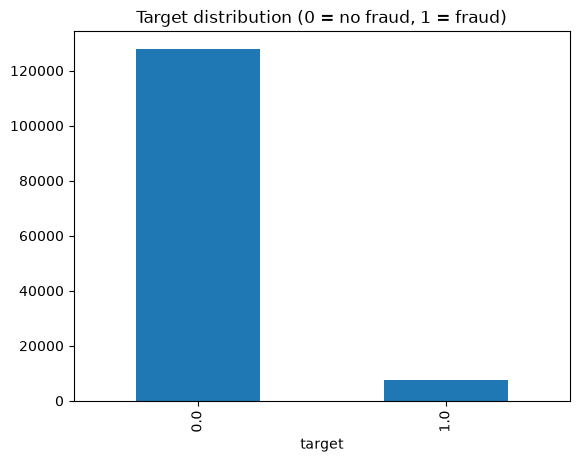

In [ ]:
# Target distribution
print(client_train["target"].value_counts(dropna=False))
print()
print(client_train["target"].value_counts(normalize=True).round(3)*100)

client_train["target"].value_counts().plot.bar(title="Target distribution (0 = no fraud, 1 = fraud)")
plt.show()


# Stage 1 End: Results & Learnings (Marker)

## 1.5 Problem Framing

### Stakeholder, goal and metric

**Stakeholder:** STEG (Tunisian Company of Electricity and Gas), revenue protection / inspection teams.

**Problem:** Some customers manipulate their electricity or gas meters, which causes large revenue losses.
On-site inspections are expensive and capacity is limited, so STEG cannot check every customer.

**Goal:** Rank customers by their probability of fraud, based on their client data and billing history,
so inspection teams visit the most suspicious customers first.

**ML task:** Binary classification at client level.
- Target `y`: `target` in `client_train.csv` (1 = fraud, 0 = no fraud), one label per client
- Signal: ~4.5 M invoices in `invoice_train.csv`, aggregated per `client_id`
- Class imbalance: 5.6 % fraud

**Metrics:**
- **Zindi:** ROC-AUC (competition metric). It measures how well the model ranks fraud above non-fraud, without a threshold.
- **Business:** Recall & F2 at the chosen threshold. A missed fraud case means lost revenue, so recall matters most;
  F2 weights recall higher but still punishes flagging everyone as fraud.
- Accuracy is useless here: predicting "never fraud" already reaches 94.4 % and finds no fraud at all.

### Rubber-duck checklist

- [x] **Do we know exactly what the target $y$ is?** → Yes: `target` in `client_train.csv`, one label per client.
- [x] **Regression, classification, clustering or anomaly detection?** → Binary classification, output as fraud probability for ranking.
- [x] **Do all features exist at prediction time?** → Not fully verifiable: the data has no fraud-detection date. Invoices issued after detection (counter replacement, corrections) could leak the label. Risk noted; check in Stage 2 (end of invoice history, fraud vs. non-fraud) and Stage 6 (suspiciously dominant features).

## 1.6 Learnings (Marker)

### Stage 1: Marker – Problem type first, then algorithm and metric

Three separate levels:

1. **Problem type:** what should come out? Decided only by what $y$ looks like, and whether there is a $y$ at all.
2. **Algorithm:** what do I compute with? (e.g. Decision Tree, LightGBM)
3. **Metric:** how do I measure if it is good? (e.g. Accuracy, Recall, RMSE)

| Problem type | $y$ looks like | Question | Example metric | Example algorithm |
| --- | --- | --- | --- | --- |
| **Regression** | a number, e.g. 1,234 kWh | How much? | RMSE, MAE | Linear Regression, Decision Tree |
| **Classification** | a class, e.g. 0/1 | Which group? | Accuracy, Recall, Precision, F1, AUC | Logistic Regression, Decision Tree |
| **Clustering** | **no $y$** | Which clients are similar? | Silhouette score | k-Means |
| **Anomaly detection** | **no $y$** (or almost none) | Who is unusual? | Precision@k | Isolation Forest |

- Accuracy is a classification metric; regression measures the distance to the true number (RMSE).
- A Decision Tree is an algorithm, not a problem type: it does regression and classification, not clustering.
- Recall and Precision count false positives/negatives, so they need the true answer (labels).
- Fraud is often an anomaly-detection problem, namely when nobody knows which clients committed fraud.

# Stage 2: Data Splitting & EDA Light

### Split strategy

- **What is split:** the clients in `client_train` (one row = one client = one `target`). The invoices follow their client via `client_id`, so all invoices of a client stay on the same side.
- **Why not split the invoices:** the same client (and their `target`) would end up in train and holdout → data leakage.
- **Stratified:** `stratify=y` keeps the fraud rate (5.6 %) equal in train and holdout.
- **No time-based split:** the `target` has no date (one label per client), so there is no "past vs. future" of clients.
- **Holdout (20 %)** stays untouched until the final evaluation in Stage 7. All EDA below uses the train part only.

## 2.1 Train/holdout split at client level

In [ ]:
# Stratified train/holdout split at client level
from sklearn.model_selection import train_test_split

train_clients, holdout_clients = train_test_split(
    client_train,
    test_size=0.2,
    stratify=client_train["target"],
    random_state=42,
)

print("train  :", train_clients.shape, f"fraud rate {train_clients['target'].mean():.2%}")
print("holdout:", holdout_clients.shape, f"fraud rate {holdout_clients['target'].mean():.2%}")

train  : (108394, 6) fraud rate 5.58%
holdout: (27099, 6) fraud rate 5.58%


In [ ]:
# Invoices follow their client
train_invoices = invoice_train[invoice_train["client_id"].isin(train_clients["client_id"])]
holdout_invoices = invoice_train[invoice_train["client_id"].isin(holdout_clients["client_id"])]

print("train invoices  :", train_invoices.shape)
print("holdout invoices:", holdout_invoices.shape)
print("clients on both sides:", len(set(train_invoices["client_id"]) & set(holdout_invoices["client_id"])))

train invoices  : (3590916, 16)
holdout invoices: (885833, 16)
clients on both sides: 0


In [ ]:
# Save holdout client IDs so the whole team uses the same split
Path("data/split").mkdir(exist_ok=True)
holdout_clients[["client_id"]].to_csv("data/split/holdout_ids.csv", index=False)

## 2.2 Leakage check: end of the invoice history

### Why this check?

The data has no fraud-detection date (Stage 1, checklist). If STEG replaces the counter or corrects invoices **after** detecting a fraud, fraud clients look different at the **end** of their history.
A large difference is a warning sign for leakage; a small one does not prove there is none.

In [ ]:
# Leakage check: do fraud clients look different at the end of their history? (train only)
inv = train_invoices.copy()
inv["invoice_date"] = pd.to_datetime(inv["invoice_date"])

per_client = inv.groupby("client_id").agg(
    last_invoice=("invoice_date", "max"),
    n_counters=("counter_number", "nunique"),
).join(train_clients.set_index("client_id")["target"])

per_client.groupby("target").agg(
    median_last_invoice=("last_invoice", "median"),
    mean_n_counters=("n_counters", "mean"),
)

,median_last_invoice,mean_n_counters
target,,
0.0,2019-05-07,1.665540
1.0,2019-05-20,2.313068


# Stage 2 End: Results & Learnings (Marker)

## 2.3 Split decisions

### Rubber-duck checklist

- [x] **Was the test set split off before any deeper analysis/scaling?** → Yes: 20 % holdout of `client_train`, split at client level before EDA.
- [x] **Is there a time dimension in the data?** → Invoices have dates, but the `target` has none (one label per client) → stratified random split at client level is valid.
- [x] **Is the target class extremely imbalanced?** → Yes, 5.6 % fraud → `stratify=y`.

## 2.4 Learnings (Marker)

Client_Train___    
INT|'disrict' - DROP//replace name "district" 
INT|'client_id', - DROP// 
INT|'client_catg',  - // -- dummyvariables -- feature
INT|'region', - //correlation matrix -- dummyvariables -- feature
DATE|'creation_date' DROP//
INT|'target' -- //drop and use it as "y"

Invoice_Train____
client_id' DROP//
invoice_date' DROP//
tarif_type' //correlation matrix
counter_number' DROP//
counter_statue' //correlation matrix (DROP//invalid rows 47!!)
counter_code' //correlation matrix
reading_remarque' //definitly a feature -- [drop rows over 100]
counter_coefficient' //sound like a feature
consommation_level_1'// keep as feature
consommation_level_2'// keep as feature
consommation_level_3'// keep as feature
consommation_level_4'// keep as feature
old_index' -- DROP// combine (consumption_missmatch = sum(consumLVL1-4) != dif(old_index, new_index)   )
new_index' -- DROP// 
months_number' DROP//
counter_type' // feature -- dummyvariable



Issue "Fraud Detection at 1 client over a bigger time period" - (RandomSelection)
Pipeline Structure

In [ ]:
# Is counter_type a useful feature? Fraud rate per type combination (train only)
types_per_client = (
    train_invoices.groupby("client_id")["counter_type"]
    .agg(lambda s: "+".join(sorted(s.unique())))   # e.g. "ELEC", "GAZ", "ELEC+GAZ"
    .rename("types")
    .to_frame()
    .join(train_clients.set_index("client_id")["target"])
)

types_per_client.groupby("types")["target"].agg(n_clients="count", fraud_rate="mean")

,n_clients,fraud_rate
types,,
ELEC,58567,0.042993
ELEC+GAZ,49273,0.071642
GAZ,554,0.009025


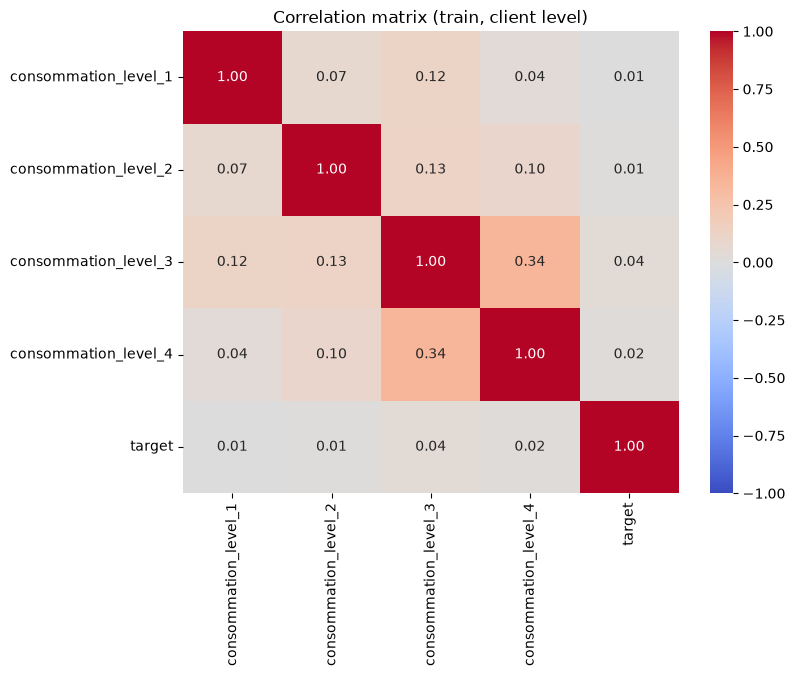

In [ ]:
# Correlation matrix of numeric client-level features (train only)
corr = per_client.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix (train, client level)")
plt.show()

In [ ]:
# Check: does the sum of the 4 levels equal new_index - old_index? (train only)
levels = ["consommation_level_1", "consommation_level_2", "consommation_level_3", "consommation_level_4"]
total = train_invoices[levels].sum(axis=1)
index_diff = train_invoices["new_index"] - train_invoices["old_index"]

print("share of invoices where sum == index difference:", (total == index_diff).mean().round(3))

share of invoices where sum == index difference: 0.996


In [ ]:
# Mismatch between levels and index difference: more common for fraud? (train only)
mismatch = train_invoices.assign(mismatch=(total != index_diff))

mismatch_per_client = (
    mismatch.groupby("client_id")["mismatch"].any()
    .to_frame()
    .join(train_clients.set_index("client_id")["target"])
)

print(mismatch_per_client.groupby("target")["mismatch"].mean().round(3))

target
0.0    0.057
1.0    0.089
Name: mismatch, dtype: float64


In [ ]:
invoice_train.describe().T

,count,mean,std,min,25%,50%,75%,max
tarif_type,4476749.0,2.012804e+01,1.347256e+01,8.0,11.0,11.0,40.0,4.500000e+01
counter_number,4476749.0,1.230587e+11,1.657267e+12,0.0,121108.0,494561.0,1115161.0,2.798115e+13
counter_code,4476749.0,1.724884e+02,1.338871e+02,0.0,5.0,203.0,207.0,6.000000e+02
reading_remarque,4476749.0,7.321702e+00,1.571654e+00,5.0,6.0,8.0,9.0,4.130000e+02
counter_coefficient,4476749.0,1.003040e+00,3.083466e-01,0.0,1.0,1.0,1.0,5.000000e+01
consommation_level_1,4476749.0,4.109795e+02,7.573080e+02,0.0,79.0,274.0,600.0,9.999100e+05
consommation_level_2,4476749.0,1.093225e+02,1.220123e+03,0.0,0.0,0.0,0.0,9.990730e+05
consommation_level_3,4476749.0,2.030620e+01,1.574239e+02,0.0,0.0,0.0,0.0,6.449200e+04
consommation_level_4,4476749.0,5.292588e+01,8.754725e+02,0.0,0.0,0.0,0.0,5.479460e+05
old_index,4476749.0,1.776700e+04,4.036693e+04,0.0,1791.0,7690.0,21660.0,2.800280e+06


In [ ]:
# Consumption levels: overview (train only)
levels = ["consommation_level_1", "consommation_level_2", "consommation_level_3", "consommation_level_4"]

summary = train_invoices[levels].describe(percentiles=[0.5, 0.9, 0.99]).T
summary["share_zero"] = (train_invoices[levels] == 0).mean()
summary

,count,mean,std,min,50%,90%,99%,max,share_zero
consommation_level_1,3590916.0,410.852872,591.757034,0.0,275.0,887.0,2176.0,126118.0,0.103896
consommation_level_2,3590916.0,106.544541,1071.424297,0.0,0.0,198.0,2035.0,819886.0,0.852942
consommation_level_3,3590916.0,20.274863,154.598720,0.0,0.0,0.0,800.0,64492.0,0.959091
consommation_level_4,3590916.0,51.940855,883.091353,0.0,0.0,0.0,1202.0,547946.0,0.979269


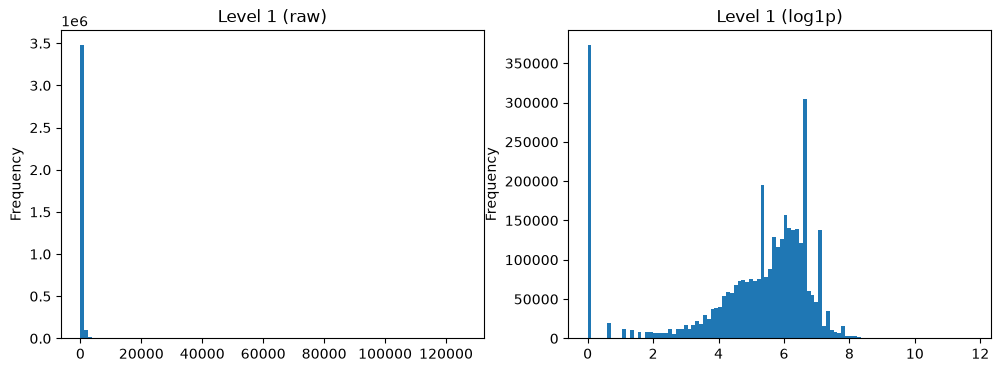

In [ ]:
# Distribution of consumption level 1 (log scale, train only)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_invoices["consommation_level_1"].plot.hist(bins=100, ax=axes[0], title="Level 1 (raw)")
np.log1p(train_invoices["consommation_level_1"]).plot.hist(bins=100, ax=axes[1], title="Level 1 (log1p)")
plt.show()

,consommation_level_1,consommation_level_2,consommation_level_3,consommation_level_4
target,,,,
0.0,354.454545,3.88,0.000000,0.0
1.0,380.700000,32.54,1.235294,0.0


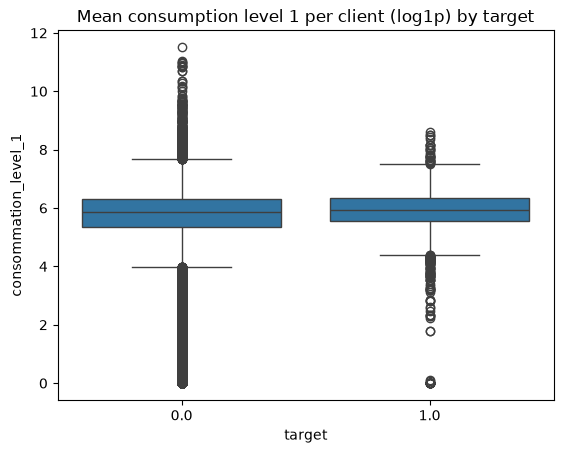

In [ ]:
# Mean consumption per client, fraud vs. no fraud (train only)
per_client = (
    train_invoices.groupby("client_id")[levels].mean()
    .join(train_clients.set_index("client_id")["target"])
)

display(per_client.groupby("target")[levels].median())

sns.boxplot(data=per_client, x="target", y=np.log1p(per_client["consommation_level_1"]))
plt.title("Mean consumption level 1 per client (log1p) by target")
plt.show()

In [ ]:
# reading_remarque: how often, and how much fraud per code? (train only)
remarque = (
    train_invoices[["client_id", "reading_remarque"]]
    .merge(train_clients[["client_id", "target"]], on="client_id")
    .groupby("reading_remarque")["target"]
    .agg(n_invoices="count", fraud_rate="mean")
    .sort_values("n_invoices", ascending=False)
)
remarque

,n_invoices,fraud_rate
reading_remarque,,
6,1788447,0.076343
9,1135826,0.079774
8,666100,0.081303
7,515,0.001942
203,15,0.000000
413,12,0.000000
5,1,0.000000


In [ ]:
invoice_train["reading_remarque"].value_counts()
# invoice_test["reading_remarque"].value_counts()

reading_remarque
6      2230939
9      1416992
8       828123
7          661
203         15
413         12
207          6
5            1
Name: count, dtype: int64

In [ ]:
client_train.groupby("disrict")["region"].unique().apply(sorted)

disrict
60                                           [101, 199]
62    [301, 302, 303, 304, 305, 307, 308, 309, 310, ...
63    [101, 305, 306, 308, 311, 312, 313, 372, 379, ...
69                       [103, 104, 105, 106, 107, 206]
Name: region, dtype: object

In [ ]:
# Regions that appear in only one of the two files
train_regions = set(client_train["region"])
test_regions = set(client_test["region"])

print("only in train:", sorted(train_regions - test_regions))
print("only in test :", sorted(test_regions - train_regions))

only in train: [199]
only in test : []


In [ ]:
print(client_train["disrict"].value_counts())

disrict
62    40353
69    34231
60    31922
63    28987
Name: count, dtype: int64


In [ ]:
print(client_train["region"].value_counts())
print(client_test["region"].value_counts())
# print(invoice_train.duplicated().sum())     #drop duplicated rows


region
101    33770
104    12865
311    12406
107     9998
301     9544
103     8964
306     6044
303     5982
310     4851
312     4379
302     4311
304     3828
309     3669
307     3376
305     2716
313     2076
371     2065
105     1645
308      841
106      706
372      644
379      583
399      175
206       53
199        2
Name: count, dtype: int64
region
101    14480
104     5558
311     5265
107     4257
301     4181
103     3848
303     2615
306     2596
310     1973
312     1840
302     1781
304     1669
309     1614
307     1510
305     1162
313      894
371      881
105      678
308      341
106      325
372      262
379      258
399       59
206       22
Name: count, dtype: int64
